# 05 — LLM Gateway Economics: Prefill vs. Decode Latency & Cache ROI
Audits why **autoregressive output decoding** dominates end-to-end LLM latency (3,000-token policy prompt benchmark), quantifies cost savings across compact JSON schemas, fast model routing, and entity-safe caching, and verifies Python <-> Go entity guardrail parity.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
ROOT_DIR = next(p for p in [cwd, *cwd.parents] if (p / 'feature_contract.json').exists())
ARTIFACTS_DIR = ROOT_DIR / 'artifacts'

bench_df = pd.DataFrame(json.loads((ARTIFACTS_DIR / 'benchmark_summary.json').read_text()))
golden = json.loads((ARTIFACTS_DIR / 'golden_fixtures.json').read_text())
guard_df = pd.DataFrame(golden['guard_cases'])

print(f"Schema Version: {golden['schema_version']} | Schema Hash: {golden['schema_hash']}")
display(bench_df)
display(guard_df)

Schema Version: v1.0.0 | Schema Hash: 6b0739238375


,strategy,prefill_ms,decode_ms,total_ms,cost_per_1k_reqs_usd
0,1. Baseline (3k in / 800 verbose out),250.0,7272.7,7567.7,0.930
1,2. Naive Half-Input (1.5k in / 800 out),125.0,7272.7,7442.7,0.705
2,3. Compact JSON Schema (3k in / 80 out),250.0,727.3,1022.3,0.498
3,4. Compact + Fast Model (3k in / 80 out),187.5,500.0,732.5,0.332
4,5. Gateway Cache Hit (Exact / FAQ Vector),0.0,0.0,0.4,0.000


,prompt,entity_sensitive
0,How do I reset my security PIN in the app?,False
1,What are the business hours for customer support?,False
2,Why is two-factor authentication required on l...,False
3,Can I change my delivery address before shipment?,False
4,Approve refund request for Order #10042 immedi...,True
5,Check shipment tracking status for AWB-883920,True
6,Send invoice copy to budi.santoso@example.co.id,True
7,Update WhatsApp alert number to +62 812-3456-7890,True
8,Verify borrower KTP 3171051209900004 before di...,True
9,Disburse Rp 2.500.000 to merchant settlement w...,True


Saved /home/gun/work/github.com/gunawanwijaya/apprentice/05-llm-gateway/artifacts/gateway_economics_summary.png


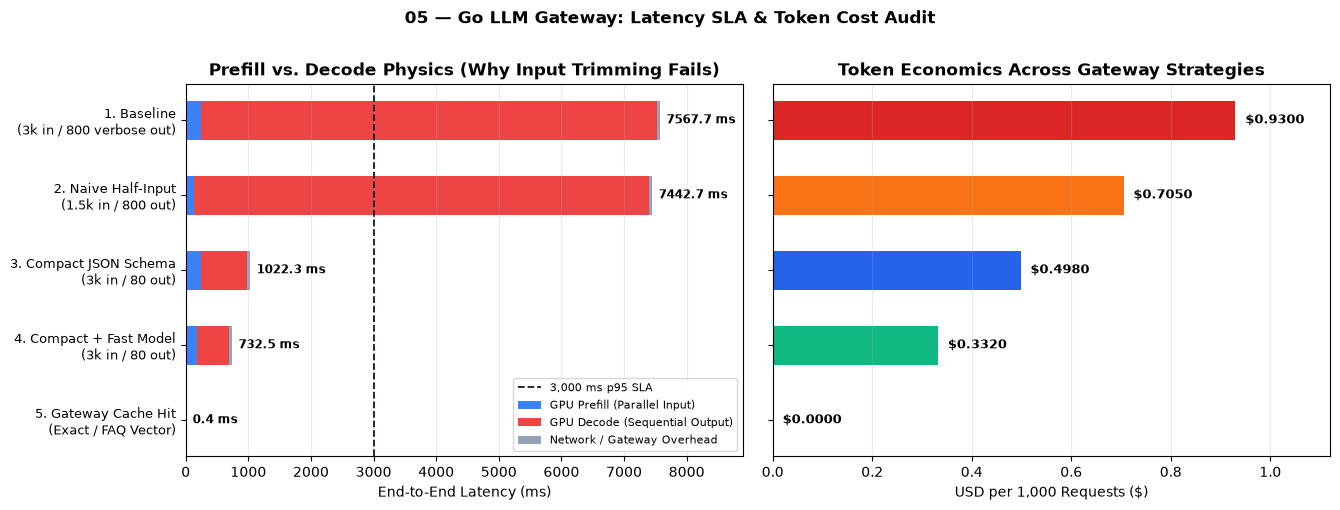

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

strategies = [s.replace(' (', '\n(') for s in bench_df['strategy']]
prefill = bench_df['prefill_ms'].to_numpy()
decode = bench_df['decode_ms'].to_numpy()
overhead = np.maximum(0.0, bench_df['total_ms'].to_numpy() - prefill - decode)
y = np.arange(len(strategies))

# Left: Stacked Latency Breakdown (Prefill vs Decode vs Network/Cache)
ax1 = axes[0]
ax1.barh(y, prefill, color='#3b82f6', height=0.52, label='GPU Prefill (Parallel Input)')
ax1.barh(y, decode, left=prefill, color='#ef4444', height=0.52, label='GPU Decode (Sequential Output)')
ax1.barh(y, overhead, left=prefill + decode, color='#94a3b8', height=0.52, label='Network / Gateway Overhead')
ax1.axvline(3000, color='#0f172a', linestyle='--', lw=1.3, label='3,000 ms p95 SLA')
ax1.set_yticks(y)
ax1.set_yticklabels(strategies, fontsize=9)
ax1.invert_yaxis()
ax1.set_xlim(0, 8900)
ax1.set_xlabel('End-to-End Latency (ms)')
ax1.set_title('Prefill vs. Decode Physics (Why Input Trimming Fails)', fontweight='bold')
for i, tot in enumerate(bench_df['total_ms']):
    ax1.text(tot + 110, i, f'{tot:.1f} ms', va='center', fontsize=8.8, fontweight='bold')
ax1.legend(loc='lower right', fontsize=8.2)
ax1.grid(axis='x', alpha=0.25)

# Right: Cost per 1,000 Requests ($ USD)
ax2 = axes[1]
costs = bench_df['cost_per_1k_reqs_usd'].to_numpy()
colors = ['#dc2626', '#f97316', '#2563eb', '#10b981', '#059669']
bars = ax2.barh(y, costs, color=colors, height=0.52)
ax2.set_yticks(y)
ax2.set_yticklabels(['' for _ in strategies])
ax2.invert_yaxis()
ax2.set_xlim(0, 1.12)
ax2.set_xlabel('USD per 1,000 Requests ($)')
ax2.set_title('Token Economics Across Gateway Strategies', fontweight='bold')
for bar, c in zip(bars, costs):
    ax2.text(c + 0.02, bar.get_y() + bar.get_height() / 2, f'${c:.4f}', va='center', fontsize=9, fontweight='bold')
ax2.grid(axis='x', alpha=0.25)

plt.suptitle('05 — Go LLM Gateway: Latency SLA & Token Cost Audit', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
out_path = ARTIFACTS_DIR / 'gateway_economics_summary.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()